# Steam share of mailbox spend

**Question:** what share of e-receipt (mailbox) spend goes to Steam, and how is that share trending year on year?

**Data:** NIQ Slice e-receipts (US, `share_niq.srs.items_extended`) and NIQ Fox e-receipts (UK, Germany, France, Italy, Spain,
`share_niq.srs.fox_transaction_items`), daily from 1 Jan 2020. All queries and rules are in section 1.

**Definitions**
- **Mailbox spend:** every priced receipt line in the panel (item price x quantity), all merchants. Lines over 10,000 (local currency)
  are dropped: Fox has mis-parsed prices in the millions. US Amazon is excluded from the total because its parsed volume jumps ~25x from
  Q4-24 and falls back in Q3-26. The same rules as the video-game wallet share in `video_games/notebooks/aaa_franchise_trends.ipynb`.
- **Steam spend:** priced lines from the Steam merchant (Slice `Steam`, Fox `steam`), classified into seven types from the item
  description (rules in section 1): games, premium editions, DLC and add-ons, in-game currency / passes / keys, subscriptions, hardware
  and wallet top-ups. Any combination of types can be selected; the default is every type except wallet top-ups. Wallet funds are later
  spent on Steam, and those purchases send their own receipts, so including top-ups counts the same spend twice.
- **Share:** Steam spend / mailbox spend over the same days, per country, in local currency (no FX).
- **Fixed merchant cohort:** an alternative denominator using only merchants with spend in every month from Jan 2021 to Oct 2026 in
  that country. It removes the effect of merchants entering the parsed panel (a new parser adds spend to the denominator only), so a
  share trend on this basis is not driven by parser coverage.
- **EU5:** the population-weighted average of the five country shares. **Combined:** the population-weighted average of all six
  (US 335m, EU5 329m).
- **Y/Y:** each day's value against the value **364 days earlier**, so weekdays line up. Windows of 7, 28 and 91 days are trailing sums,
  so the Y/Y compares like-for-like weeks.

Sections: 1. Data pull · 2. Steam share of mailbox spend · 3. Y/Y trend (364-day shift) · 4. Calendar quarters · 5. Web app

In [1]:
from datetime import date, timedelta, datetime, timezone
from pathlib import Path
import json
import polars as pl
import snowflake.connector
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from IPython.display import display

pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(-1); pl.Config.set_tbl_width_chars(240); pl.Config.set_tbl_hide_dataframe_shape(True)

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e6e5e0"
REGION_COLOR = {"US": BLUE, "EU5": ORANGE, "Combined": INK2}
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})

START = date(2020, 1, 1)
PULL_END = date(2026, 11, 17)     # last day pulled; each panel's last complete day is found in 1.2
SHOW_FROM = date(2021, 1, 1)      # Fox had ~50k active panelists before 2021, so EU shares before then are noise
MAX_LINE = 10000                  # line value cap (local currency)
COHORT_FROM, COHORT_TO = date(2021, 1, 1), date(2026, 10, 31)   # fixed cohort: spend in every month of this span
SHIFT = 364                       # Y/Y compares with the same weekday 52 weeks earlier
WINDOWS = [1, 7, 28, 91]
COUNTRY_POP = {"US": 335.0, "UK": 68.3, "DE": 84.5, "FR": 68.4, "IT": 59.0, "ES": 48.6}   # millions
EU5 = ["UK", "DE", "FR", "IT", "ES"]
REGIONS = {"US": ["US"], "EU5": EU5, "Combined": ["US"] + EU5, **{c: [c] for c in EU5}}
TYPE_NAME = {"game": "Games", "edition": "Premium editions", "dlc": "DLC / add-ons", "ingame": "In-game currency / passes / keys",
             "sub": "Subscriptions", "hardware": "Hardware", "wallet": "Wallet top-ups"}
TYPES = list(TYPE_NAME)
DEFAULT = [t for t in TYPES if t != "wallet"]   # wallet top-ups double count the purchases they later fund
DENOMS = {"all": "total", "fixed": "fixed"}

REFRESH = False    # True re-runs the Snowflake queries (~10 min on ANALYST_XL); False reads the cached parquet in data/
DATA = Path("data"); DATA.mkdir(exist_ok=True)
_con = None

def query(name, sql):
    """Run sql on Snowflake and cache the result as data/<name>.parquet (read from the cache unless REFRESH)."""
    global _con
    path = DATA / f"{name}.parquet"
    if path.exists() and not REFRESH:
        return pl.read_parquet(path)
    if _con is None:
        _con = snowflake.connector.connect(connection_name="default", warehouse="ANALYST_XL", network_timeout=7200)
    cur = _con.cursor()
    cur.execute(sql)
    df = pl.from_arrow(cur.fetch_arrow_all()).rename(str.lower)
    df.write_parquet(path)
    return df

## 1. Data pull

**Method**
- **Steam lines.** Slice `merchant_name = 'Steam'` and Fox `merchant_name = 'steam'` (EU5 countries only), priced lines up to 10,000.
  Fox repeats a line once per industry tag, so it is deduplicated to one row per merchant, order and item.
- **Types.** Applied in SQL (`TYPE_RULES` below) to the lower-cased description; Fox often prefixes the app name ("marvel rivals | 2180
  lattices"), so most rules test the item text after the last "|". First match wins:
  1. **Wallet top-ups:** "steam wallet", "wallet funds", "gift card" and its local forms. US "Steam Wallet Funds"; Fox "Digital Gift Card".
  2. **Hardware:** items starting "steam deck", "steam machine", "steam frame", "steam controller", "steam link" or "valve index".
  3. **Subscriptions:** "subscription", "membership", EA Play, VRChat+, one-month / 12-month passes (VRChat+, FFXIV, ESO Plus, Fallout 1st).
  4. **In-game currency / passes / keys:** currency packs (an amount of 100+ or a named currency: Lattices, Auric Cells, Raider Tokens,
     Echo Beads, coins, credits, gems), "bonus", Counter-Strike case keys (all languages), Armory / battle / premium passes, Prime upgrade.
  5. **Premium editions:** "deluxe / premium / ultimate / gold / vault / collector's / complete / definitive ... edition".
  6. **DLC / add-ons:** "DLC", soundtrack, expansion, season pass, supporter pack, "chapter n", cosmetic sets / skins, and "Game - Subtitle" items.
  7. **Games:** everything else (base games, bundles).
- The rules are keyword heuristics: some currency packs in local languages still fall into Games, and some "Game - Subtitle" base games
  into DLC. Section 1 shows the largest items per type so the rules can be checked.
- **Mailbox spend.** All merchants, same price rules; US excludes Amazon. Fox deduplicated as above.
- **Fixed merchant cohort.** Per country, the merchants with priced spend in every calendar month from Jan 2021 to Oct 2026 (70 months).
  Their daily spend is the alternative denominator. Merchants that start being parsed later, or that drop out, are left out.

In [2]:
sql_list = lambda xs: ", ".join(f"'{x}'" for x in xs)

# (type, column, POSIX regex) - first match wins, anything unmatched is a game. d = description, item = text after the last "|".
# No backslashes or quotes, so the patterns pass through Python and Snowflake unchanged; [^a-z] stands in for a word boundary.
TYPE_RULES = [
    ("wallet", "d", "steam wallet|wallet funds|gift ?card|giftcard|carte[- ]cadeau|guthaben|geschenkkarte|carta regalo|buono regalo|tarjeta regalo"),
    ("hardware", "item", "^(steam (deck|machine|frame|controller|link)|valve index)"),
    ("sub", "d", "subscription|membership|ea play|vrchat[+]|vrc[+]|[(]one month[)]|1[ -]month|12[ -]month"),
    ("ingame", "item", "^[1-9][0-9,.]{2,}|[0-9] ?[a-z0-9() +!*.-]*(coins?|credits|gems|crystals|munzen|tokens|lattices|cells|beads|lunites|atoms)([^a-z]|$)"
                       "|(^|[^a-z])bonus([^a-z]|$)|case key|kistenschl|cl. de caisse|chiave della cassa|llave de caja|(^|[^a-z0-9])[0-9]+ ?x "
                       "|armou?ry pass|arsenal ?pass|arsenal-pass|passe de l.arsenal|pase de la armer|battle ?pass|premium pass|elite pass"
                       "|(^|[^a-z])(v-bucks|g-coin|bfc|cp)([^a-z]|$)|point pack|crystal pack|prime.status.upgrade|recharge"),
    ("edition", "item", "(deluxe|premium|ultimate|gold|vault|collector.?s|complete|definitive|royal|anniversary|special|supporter|legendary) edition"
                        "|edition (deluxe|ultimate)"),
    ("dlc", "item", "(^|[^a-z])dlc([^a-z]|$)|soundtrack|expansion|season pass|supporter pack| - [a-z]|phantom liberty|chapter [0-9]"
                    "|(^|[^a-z])set([^a-z]|$)|(^|[^a-z])skins?([^a-z]|$)|costume|outfit|cosmetic"),
]
STEAM_TYPE = ("case\n" + "".join(f"    when regexp_instr({col}, '{pat}') > 0 then '{t}'\n" for t, col, pat in TYPE_RULES)
              + "    else 'game'\nend")

STEAM_SQL = f"""
with lines as (
    select 'US' as country, order_date, lower(description) as d, item_price * nvl(item_quantity, 1) as spend
    from share_niq.srs.items_extended
    where merchant_name = 'Steam' and order_date between '{START}' and '{PULL_END}'
      and item_price > 0 and item_price * nvl(item_quantity, 1) <= {MAX_LINE}
    union all
    select country, order_date, d, spend from (
        select upper(country) as country, try_to_date(order_date) as order_date, lower(product_name) as d,
               item_price * nvl(item_quantity, 1) as spend
        from share_niq.srs.fox_transaction_items
        where merchant_name = 'steam' and upper(country) in ({sql_list(EU5)})
          and try_to_date(order_date) between '{START}' and '{PULL_END}'
          and item_price > 0 and item_price * nvl(item_quantity, 1) <= {MAX_LINE}
        qualify row_number() over (partition by merchant_name, order_id, item_id order by industry) = 1)
)
, typed as (select *, {STEAM_TYPE} as grp from (select *, trim(regexp_replace(d, '^.*[|]', '')) as item from lines))
"""
STEAM_DAILY_SQL = STEAM_SQL + "select country, order_date, grp, sum(spend) as spend, count(*) as n_lines from typed group by all"
STEAM_ITEMS_SQL = STEAM_SQL + f"""select iff(country = 'US', 'US', 'EU5') as region, grp, item, sum(spend) as spend, count(*) as n_lines
from typed where order_date > dateadd(day, -365, '{PULL_END}'::date) group by all"""

TOTAL_SQL = f"""
select 'US' as country, order_date, sum(item_price * nvl(item_quantity, 1)) as total
from share_niq.srs.items_extended
where order_date between '{START}' and '{PULL_END}' and item_price > 0 and item_price * nvl(item_quantity, 1) <= {MAX_LINE}
  and merchant_name <> 'Amazon'
group by all
union all
select country, order_date, sum(spend) from (
    select upper(country) as country, try_to_date(order_date) as order_date, item_price * nvl(item_quantity, 1) as spend
    from share_niq.srs.fox_transaction_items
    where upper(country) in ({sql_list(EU5)}) and try_to_date(order_date) between '{START}' and '{PULL_END}'
      and item_price > 0 and item_price * nvl(item_quantity, 1) <= {MAX_LINE}
    qualify row_number() over (partition by merchant_name, order_id, item_id order by industry) = 1)
group by all
"""

N_MONTHS = (COHORT_TO.year - COHORT_FROM.year) * 12 + COHORT_TO.month - COHORT_FROM.month + 1
FIXED_SQL = f"""
with lines as (
    select 'US' as country, merchant_name, order_date, item_price * nvl(item_quantity, 1) as spend
    from share_niq.srs.items_extended
    where order_date between '{START}' and '{PULL_END}' and item_price > 0 and item_price * nvl(item_quantity, 1) <= {MAX_LINE}
      and merchant_name <> 'Amazon'
    union all
    select country, merchant_name, order_date, spend from (
        select upper(country) as country, merchant_name, try_to_date(order_date) as order_date, item_price * nvl(item_quantity, 1) as spend
        from share_niq.srs.fox_transaction_items
        where upper(country) in ({sql_list(EU5)}) and try_to_date(order_date) between '{START}' and '{PULL_END}'
          and item_price > 0 and item_price * nvl(item_quantity, 1) <= {MAX_LINE}
        qualify row_number() over (partition by merchant_name, order_id, item_id order by industry) = 1)
),
cohort as (
    select country, merchant_name from lines
    where order_date between '{COHORT_FROM}' and '{COHORT_TO}' and merchant_name is not null
    group by all having count(distinct date_trunc('month', order_date)) = {N_MONTHS}
),
sizes as (select country, count(*) as n_merchants from cohort group by all)
select l.country, l.order_date, sum(l.spend) as fixed, any_value(s.n_merchants) as n_merchants
from lines l join cohort k on k.country = l.country and k.merchant_name = l.merchant_name
join sizes s on s.country = l.country
group by all
"""

steam_raw = query("steam_daily_types", STEAM_DAILY_SQL)
steam_items = query("steam_items_12m", STEAM_ITEMS_SQL)
total_raw = query("mailbox_total_daily", TOTAL_SQL)
fixed_raw = query("mailbox_fixed_daily", FIXED_SQL)
print("Fixed cohort merchants:", dict(fixed_raw.group_by("country").agg(pl.col("n_merchants").first()).sort("country").iter_rows()))
print("Steam spend by type, last 365 days: % of Steam spend and average line value (local currency)")
display(steam_items.group_by("region", "grp").agg(pl.col("spend", "n_lines").sum())
        .with_columns(pct=(pl.col("spend") / pl.col("spend").sum().over("region") * 100).round(1), avg=(pl.col("spend") / pl.col("n_lines")).round(2))
        .pivot("region", index="grp", values=["pct", "avg"]).with_columns(pl.col("grp").replace_strict(TYPE_NAME)).sort("pct_US", descending=True))
print("Largest items per type, last 365 days (check of the rules)")
display(steam_items.sort("spend", descending=True).group_by("region", "grp", maintain_order=True).head(6)
        .group_by("grp", "region").agg(items=pl.col("item").str.slice(0, 40).str.join(" · ")).sort("grp", "region"))

Fixed cohort merchants: {'DE': 358, 'ES': 201, 'FR': 530, 'IT': 240, 'UK': 393, 'US': 799}
Steam spend by type, last 365 days: % of Steam spend and average line value (local currency)


grp,pct_US,pct_EU5,avg_US,avg_EU5
str,f64,f64,f64,f64
"""Games""",53.6,66.4,11.72,9.9
"""Wallet top-ups""",17.5,0.4,21.39,22.56
"""In-game currency / passes / ke…",10.5,14.3,14.8,10.47
"""Premium editions""",6.9,6.4,27.22,21.01
"""DLC / add-ons""",6.9,9.5,8.03,7.56
"""Hardware""",4.2,2.8,422.17,419.88
"""Subscriptions""",0.5,0.3,11.64,12.24


Largest items per type, last 365 days (check of the rules)


grp,region,items
str,str,str
"""dlc""","""EU5""","""cyberpunk 2077: phantom libert…"
"""dlc""","""US""","""cyberpunk 2077: phantom libert…"
"""edition""","""EU5""","""forza horizon 6 premium editio…"
"""edition""","""US""","""forza horizon 6 premium editio…"
"""game""","""EU5""","""subnautica 2 · forza horizon 6…"
"""game""","""US""","""arc raiders · subnautica 2 · c…"
"""hardware""","""EU5""","""steam deck 512 gb oled · steam…"
"""hardware""","""US""","""steam deck 512 gb oled · steam…"
"""ingame""","""EU5""","""2180 lattices · armory pass · …"


### 1.1 Last complete day per panel

Receipts arrive over several days, so the last days of a pull are incomplete. A country's last complete day is the latest day whose mailbox
spend is at least 75% of the median of the 28 days before it, and at most two days before the pull (Slice's newest days look complete
on totals but are still filling). EU5 and Combined end on the earliest of their countries' last days.

In [3]:
def last_complete(g):
    g = g.sort("order_date").with_columns(ref=pl.col("total").shift(1).rolling_median(28))
    ok = g.filter(pl.col("total") >= 0.75 * pl.col("ref"))
    return min(ok["order_date"].max(), PULL_END - timedelta(days=2))

END = {c: last_complete(total_raw.filter(pl.col("country") == c)) for c in COUNTRY_POP}
REGION_END = {r: min(END[c] for c in cs) for r, cs in REGIONS.items()}
print("Last complete day:", {c: str(d) for c, d in END.items()})
display(total_raw.filter(pl.col("order_date") > PULL_END - timedelta(days=10)).sort("order_date")
        .pivot("country", index="order_date", values="total").with_columns(pl.exclude("order_date").round(0)))

Last complete day: {'US': '2026-11-15', 'UK': '2026-11-08', 'DE': '2026-11-08', 'FR': '2026-11-08', 'IT': '2026-11-08', 'ES': '2026-11-08'}


order_date,US,UK,FR,IT,DE,ES
date,f64,f64,f64,f64,f64,f64
2026-11-08,2.7669369e7,2.776913e6,3.096321e6,1.489114e6,3.273751e6,972339.0
2026-11-09,2.8847469e7,1.440906e6,1.774429e6,717716.0,1.51361e6,555408.0
2026-11-10,2.8091484e7,73335.0,38619.0,17272.0,37902.0,18730.0
2026-11-11,2.8224863e7,null,null,null,null,null
2026-11-12,2.8633547e7,null,null,null,null,null
2026-11-13,3.0605988e7,null,null,null,null,null
2026-11-14,2.9083969e7,null,null,null,null,null
2026-11-15,2.9257677e7,null,null,null,null,null
2026-11-16,2.8298838e7,null,null,null,null,null


### 1.2 Daily frame

One row per country and day from 1 Jan 2020 to that country's last complete day, with Steam spend by type, mailbox spend (all merchants)
and fixed-cohort mailbox spend. Days with no Steam receipt count as 0.

In [4]:
steam_w = steam_raw.pivot("grp", index=["country", "order_date"], values="spend", aggregate_function="sum")
for g in TYPES:
    if g not in steam_w.columns: steam_w = steam_w.with_columns(pl.lit(0.0).alias(g))
frames = []
for c, end in END.items():
    days = pl.DataFrame({"order_date": pl.date_range(START, end, eager=True)}).with_columns(country=pl.lit(c))
    frames.append(days)
daily = (pl.concat(frames).join(total_raw, on=["country", "order_date"], how="left")
         .join(steam_w, on=["country", "order_date"], how="left")
         .join(fixed_raw.select("country", "order_date", "fixed"), on=["country", "order_date"], how="left")
         .with_columns(pl.col("total", "fixed", *TYPES).fill_null(0.0))
         .sort("country", "order_date"))
print("Type mix by year: % of Steam spend (US | UK)")
for c in ["US", "UK"]:
    display(daily.filter(pl.col("country") == c, pl.col("order_date") >= SHOW_FROM).group_by(y=pl.col("order_date").dt.year())
            .agg(pl.col(TYPES).sum()).with_columns(pl.col(TYPES) / pl.sum_horizontal(TYPES) * 100).with_columns(pl.col(TYPES).round(1))
            .rename(TYPE_NAME).sort("y"))

Type mix by year: % of Steam spend (US | UK)


y,Games,Premium editions,DLC / add-ons,In-game currency / passes / keys,Subscriptions,Hardware,Wallet top-ups
i32,f64,f64,f64,f64,f64,f64,f64
2021,58.0,6.9,7.8,10.4,0.5,0.5,16.0
2022,55.4,5.5,7.0,10.8,0.5,4.3,16.5
2023,52.1,7.2,6.6,10.2,0.4,6.7,16.7
2024,54.8,5.9,8.2,10.2,0.5,4.5,15.9
2025,53.9,7.1,6.4,11.1,0.5,3.5,17.5
2026,53.3,6.9,6.8,10.7,0.5,3.9,17.9


y,Games,Premium editions,DLC / add-ons,In-game currency / passes / keys,Subscriptions,Hardware,Wallet top-ups
i32,f64,f64,f64,f64,f64,f64,f64
2021,63.7,6.4,10.2,17.2,0.5,1.6,0.5
2022,55.9,5.1,9.7,12.1,0.3,16.5,0.3
2023,45.5,5.1,7.9,15.7,0.2,25.3,0.3
2024,56.6,5.4,9.9,16.4,0.3,11.1,0.4
2025,60.4,6.3,8.6,18.0,0.3,5.9,0.6
2026,60.1,6.4,8.7,18.5,0.3,5.3,0.5


## 2. Steam share of mailbox spend

**Method**
- Per country: Steam spend / mailbox spend (all merchants, or the fixed merchant cohort) over a trailing window of 1, 7, 28 or 91 days (sums, not an average of daily shares).
- Regions: EU5 and Combined are population-weighted averages of the country shares, on days every member country has data.
- The functions below are the same calculation the web app runs in the browser (section 5 checks they agree).

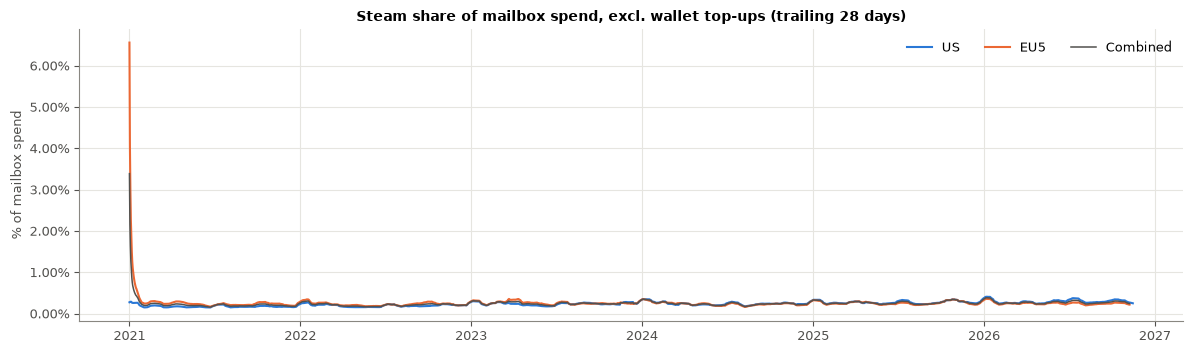

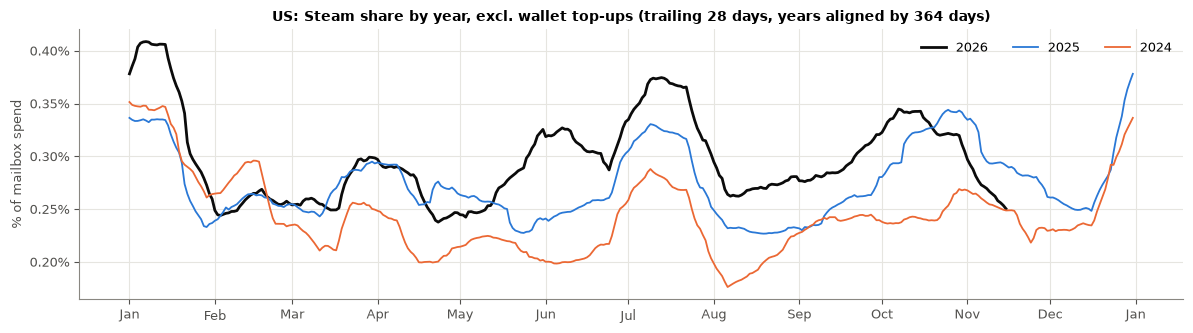

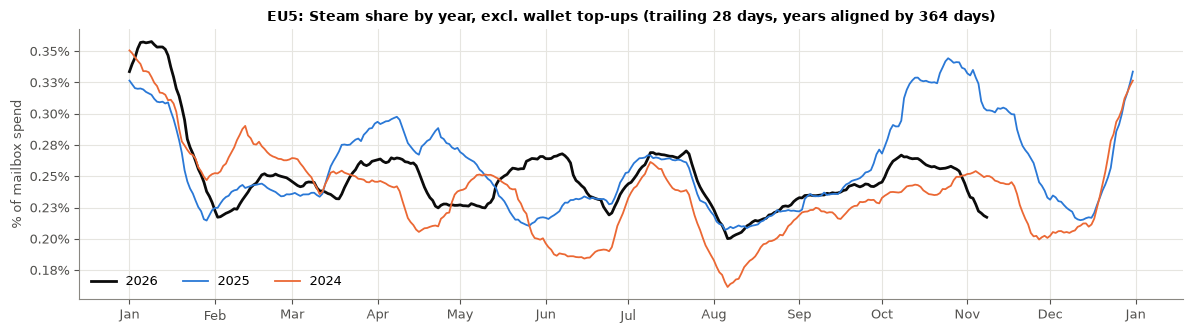

In [5]:
def country_window(types=DEFAULT, window=28, denom="all"):
    return (daily.with_columns(steam=pl.sum_horizontal(types), total=pl.col(DENOMS[denom]))
            .with_columns(pl.col("steam", "total").rolling_sum(window).over("country"))
            .with_columns(share=pl.col("steam") / pl.col("total")))

def regional(types=DEFAULT, window=28, shift=SHIFT, denom="all"):
    """Share and Y/Y per region and day. Y/Y of spend = population-weighted mean of the countries' Y/Y."""
    cw = country_window(types, window, denom)
    prior = cw.select("country", order_date=pl.col("order_date") + timedelta(days=shift),
                      share_ly=pl.col("share"), steam_ly=pl.col("steam"), total_ly=pl.col("total"))
    cw = (cw.join(prior, on=["country", "order_date"], how="left")
          .with_columns(share_yoy=pl.col("share") / pl.col("share_ly") - 1, steam_yoy=pl.col("steam") / pl.col("steam_ly") - 1,
                        total_yoy=pl.col("total") / pl.col("total_ly") - 1,
                        w=pl.col("country").replace_strict(COUNTRY_POP, return_dtype=pl.Float64)))
    out = []
    for r, cs in REGIONS.items():
        g = (cw.filter(pl.col("country").is_in(cs), pl.col("share").is_not_null())
             .group_by("order_date").agg(n=pl.len(), w=pl.col("w").sum(),
                 **{k: (pl.col(k) * pl.col("w")).sum() for k in ["share", "share_ly", "steam_yoy", "total_yoy"]})
             .filter(pl.col("n") == len(cs))
             .with_columns(pl.col("share", "share_ly", "steam_yoy", "total_yoy") / pl.col("w"))
             .with_columns(share_yoy=pl.col("share") / pl.col("share_ly") - 1, region=pl.lit(r)))
        out.append(g.select("region", "order_date", "share", "share_ly", "share_yoy", "steam_yoy", "total_yoy"))
    return pl.concat(out).sort("region", "order_date")

def lines_chart(df, col, title, ylabel, regions=("US", "EU5", "Combined"), since=SHOW_FROM, pct=True, zero=False):
    fig, ax = plt.subplots(figsize=(12, 3.6))
    for r in regions:
        g = df.filter(pl.col("region") == r, pl.col("order_date") >= since).sort("order_date")
        ax.plot(g["order_date"], g[col] * 100, color=REGION_COLOR.get(r, MUTED), lw=1.5 if r != "Combined" else 1.1, label=r)
    if zero: ax.axhline(0, color=INK2, lw=0.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=2 if not zero else 0))
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=10))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))
    ax.set_title(title); ax.set_ylabel(ylabel); ax.legend(frameon=False, ncols=3)
    fig.tight_layout(); plt.show()

def year_chart(df, col, region, title, ylabel, years=3, pct_dec=2, zero=False):
    """One line per year on a Jan-Dec axis. Earlier years are shifted forward by multiples of 364 days, as on the web page, so the
    vertical gap between adjacent lines is the Y/Y."""
    g = df.filter(pl.col("region") == region).drop_nulls(col)
    y1 = g["order_date"].max().year
    fig, ax = plt.subplots(figsize=(12, 3.4))
    for k, colour in zip(range(years), [INK, BLUE, ORANGE, AQUA, YELLOW]):
        h = (g.with_columns(x=pl.col("order_date") + timedelta(days=SHIFT * k))
             .filter(pl.col("x").dt.year() == y1, pl.col("order_date") >= SHOW_FROM))
        ax.plot(h["x"], h[col] * 100, color=colour, lw=2 if k == 0 else 1.3, label=str(y1 - k))
    if zero: ax.axhline(0, color=INK2, lw=0.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=pct_dec))
    ax.xaxis.set_major_locator(mdates.MonthLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_title(title); ax.set_ylabel(ylabel); ax.legend(frameon=False, ncols=years)
    fig.tight_layout(); plt.show()

r28 = regional(DEFAULT, 28)
lines_chart(r28, "share", "Steam share of mailbox spend, excl. wallet top-ups (trailing 28 days)", "% of mailbox spend")
for r in ["US", "EU5"]:
    year_chart(r28, "share", r, f"{r}: Steam share by year, excl. wallet top-ups (trailing 28 days, years aligned by 364 days)", "% of mailbox spend")

In [6]:
# share Y/Y by type: which kinds of Steam spend drive the trend (US and EU5, trailing 91 days, latest day)
rows = []
for t in TYPES:
    g = regional([t], 91)
    for r in ["US", "EU5"]:
        last = g.filter(pl.col("region") == r).drop_nulls("share_yoy").row(-1, named=True)
        rows.append({"type": TYPE_NAME[t], "region": r, "share_bp": round(last["share"] * 1e4, 2), "yoy": round(last["share_yoy"] * 100, 1)})
print("By type: share of mailbox spend (basis points) and share Y/Y, trailing 91 days to each region's last day")
display(pl.DataFrame(rows).pivot("region", index="type", values=["share_bp", "yoy"]))

By type: share of mailbox spend (basis points) and share Y/Y, trailing 91 days to each region's last day


type,share_bp_US,share_bp_EU5,yoy_US,yoy_EU5
str,f64,f64,f64,f64
"""Games""",18.76,16.39,-3.7,-12.5
"""Premium editions""",2.5,1.61,-5.1,-13.9
"""DLC / add-ons""",2.15,2.29,5.3,4.2
"""In-game currency / passes / ke…",3.27,2.86,-7.1,-38.6
"""Subscriptions""",0.17,0.08,-2.0,29.2
"""Hardware""",2.28,0.74,151.3,-8.8
"""Wallet top-ups""",5.84,0.09,-2.9,79.1


## 3. Y/Y trend (364-day shift)

**Method**
- **Share Y/Y** = share over the trailing window ending on a day ÷ share over the same window 364 days earlier − 1.
- Mailbox spend moves with panel size (Slice orders are down 13–18% Y/Y), which the share removes, so the share is the trend to read.

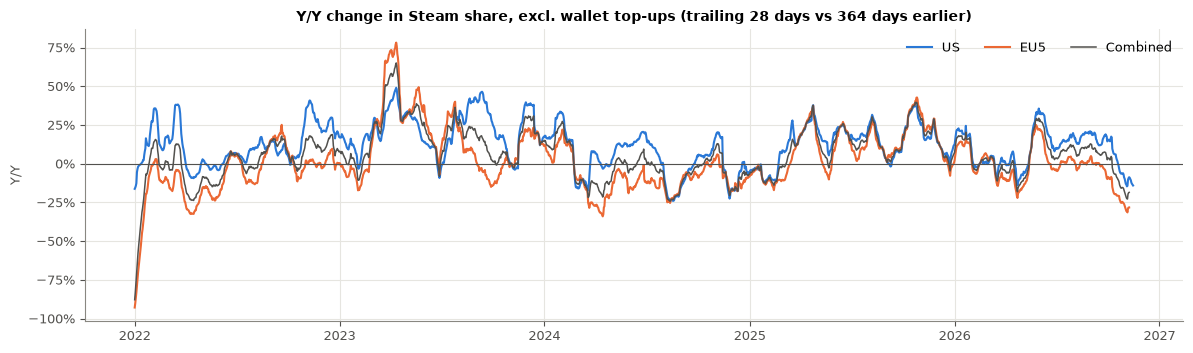

In [7]:
lines_chart(r28.filter(pl.col("order_date") >= date(2022, 1, 1)), "share_yoy",
            "Y/Y change in Steam share, excl. wallet top-ups (trailing 28 days vs 364 days earlier)", "Y/Y", zero=True)

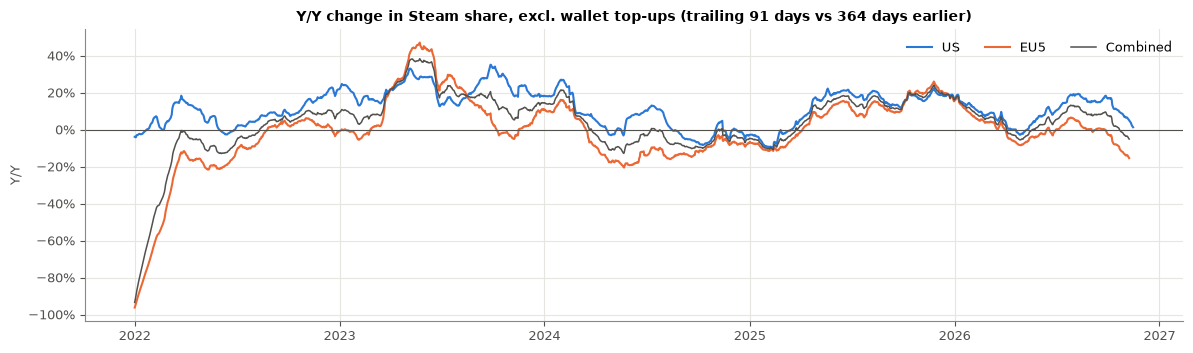

In [8]:
r91 = regional(DEFAULT, 91)
lines_chart(r91.filter(pl.col("order_date") >= date(2022, 1, 1)), "share_yoy",
            "Y/Y change in Steam share, excl. wallet top-ups (trailing 91 days vs 364 days earlier)", "Y/Y", zero=True)

## 4. Calendar quarters

Share over each calendar quarter's days (the current quarter to date), and Y/Y against the same days shifted back 364 days.

In [9]:
def quarterly(types=DEFAULT, denom="all"):
    d = daily.with_columns(steam=pl.sum_horizontal(types), total=pl.col(DENOMS[denom]))
    prior = d.select("country", order_date=pl.col("order_date") + timedelta(days=SHIFT), steam_ly="steam", total_ly="total")
    d = d.join(prior, on=["country", "order_date"], how="left").with_columns(q=pl.col("order_date").dt.truncate("1q"))
    rows = []
    for r, cs in REGIONS.items():
        end = REGION_END[r]
        g = (d.filter(pl.col("country").is_in(cs), pl.col("order_date") <= end)
             .group_by("country", "q").agg(pl.col("steam", "total", "steam_ly", "total_ly").sum(), days=pl.len())
             .with_columns(share=pl.col("steam") / pl.col("total"), share_ly=pl.col("steam_ly") / pl.col("total_ly"),
                           w=pl.col("country").replace_strict(COUNTRY_POP, return_dtype=pl.Float64))
             .group_by("q").agg(share=(pl.col("share") * pl.col("w")).sum() / pl.col("w").sum(),
                                share_ly=(pl.col("share_ly") * pl.col("w")).sum() / pl.col("w").sum(), days=pl.col("days").max()))
        rows.append(g.with_columns(region=pl.lit(r)))
    return (pl.concat(rows).with_columns(yoy=pl.col("share") / pl.col("share_ly") - 1,
                                         label=pl.col("q").dt.year().cast(pl.Utf8) + "Q" + pl.col("q").dt.quarter().cast(pl.Utf8))
            .filter(pl.col("q") >= date(2021, 1, 1)).sort("region", "q"))

qt = quarterly(DEFAULT)
for what, col, k in [("Share of mailbox spend (%)", "share", 100), ("Y/Y change in share (%)", "yoy", 100)]:
    print(what, "(excl. wallet top-ups)")
    display(qt.filter(pl.col("q") >= date(2024, 1, 1), pl.col("region").is_in(["US", "EU5", "Combined"]))
            .with_columns(v=(pl.col(col) * k).round(3 if col == "share" else 1)).pivot("label", index="region", values="v", sort_columns=True))

Share of mailbox spend (%) (excl. wallet top-ups)


region,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Combined""",0.255,0.218,0.221,0.26,0.256,0.255,0.247,0.306,0.262,0.269,0.267,0.27
"""EU5""",0.257,0.218,0.215,0.253,0.25,0.245,0.239,0.295,0.25,0.244,0.235,0.242
"""US""",0.253,0.219,0.228,0.268,0.263,0.265,0.256,0.317,0.274,0.293,0.299,0.284


Y/Y change in share (%) (excl. wallet top-ups)


region,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Combined""",-2.1,-3.1,-9.3,-5.2,1.9,16.0,12.5,16.5,2.8,5.3,7.7,-16.9
"""EU5""",-8.6,-14.0,-11.8,-7.3,-1.6,12.1,11.9,15.6,0.3,-0.2,-1.9,-26.2
"""US""",5.5,10.4,-6.8,-3.2,5.4,19.8,12.9,17.3,5.2,10.2,16.5,-10.0


### 4.1 Does merchant coverage drive the trend? All merchants vs a fixed merchant cohort

A new merchant parser adds spend to the denominator but not to Steam, so it lowers the Steam share without any change in behaviour. The
fixed cohort keeps only merchants seen in every month from Jan 2021 to Oct 2026.
- **Coverage:** the cohort's share of all mailbox spend. If it falls over time, spend is coming from merchants added later.
- **Comparison:** quarterly share Y/Y on both denominators. The gap is the effect of merchant coverage changes.

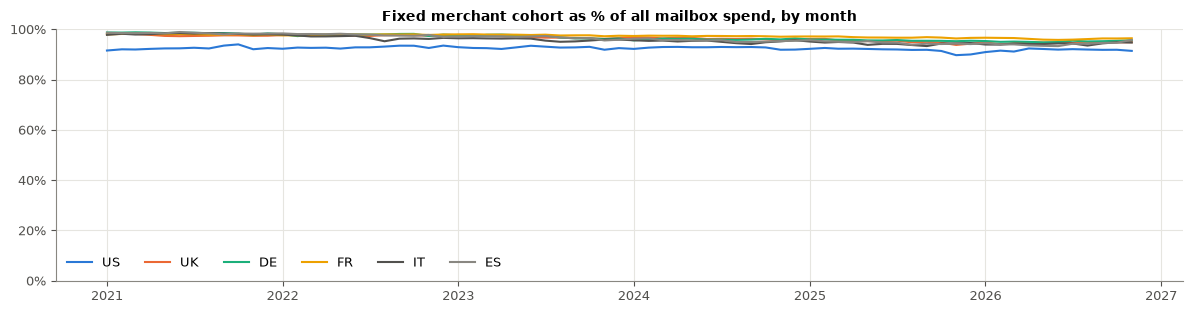

y,DE,ES,FR,IT,UK,US
i32,f64,f64,f64,f64,f64,f64
2021,98.7,98.9,98.1,98.5,97.3,92.4
2022,98.0,98.0,97.9,97.4,97.5,92.8
2023,97.6,97.2,97.7,96.3,96.9,93.5
2024,95.9,95.6,97.4,95.5,96.2,92.9
2025,95.6,94.7,96.7,94.2,95.3,92.1
2026,94.9,93.3,95.8,94.4,94.7,91.9


Share Y/Y, excl. wallet top-ups: all merchants


region,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Combined""",21.3,19.1,17.6,14.3,-2.1,-3.1,-9.3,-5.2,1.9,16.0,12.5,16.5,2.8,5.3,7.7,-16.9
"""EU5""",20.9,24.1,4.5,10.6,-8.6,-14.0,-11.8,-7.3,-1.6,12.1,11.9,15.6,0.3,-0.2,-1.9,-26.2
"""US""",21.6,13.3,34.1,18.1,5.5,10.4,-6.8,-3.2,5.4,19.8,12.9,17.3,5.2,10.2,16.5,-10.0


Share Y/Y, excl. wallet top-ups: fixed merchant cohort


region,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Combined""",21.4,19.1,18.6,15.5,-1.3,-2.3,-8.9,-4.9,2.3,17.0,13.5,18.3,4.0,5.8,7.9,-17.1
"""EU5""",21.3,24.6,5.4,12.0,-7.6,-12.9,-11.0,-6.9,-1.3,12.9,12.7,16.7,1.3,0.7,-1.7,-26.4
"""US""",21.5,13.1,34.5,19.0,5.5,10.3,-6.9,-3.0,5.8,20.8,14.2,19.7,6.5,10.2,16.4,-10.6


Share Y/Y, excl. wallet top-ups: gap (all − fixed), pp


region,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Combined""",-0.1,-0.0,-1.0,-1.2,-0.8,-0.8,-0.4,-0.3,-0.4,-1.0,-1.1,-1.8,-1.2,-0.5,-0.2,0.2
"""EU5""",-0.3,-0.5,-0.9,-1.3,-1.1,-1.0,-0.8,-0.3,-0.4,-0.8,-0.8,-1.2,-1.0,-0.9,-0.2,0.2
"""US""",0.2,0.2,-0.4,-0.9,-0.0,0.1,0.1,-0.3,-0.3,-0.9,-1.3,-2.4,-1.3,-0.0,0.1,0.7


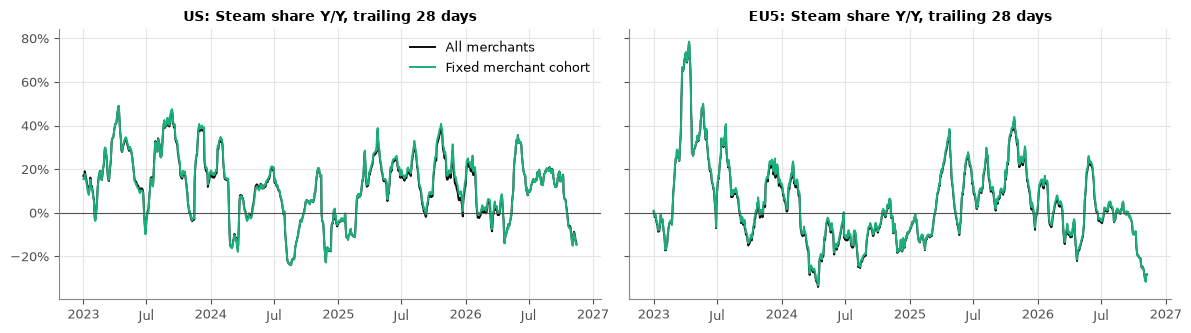

In [10]:
cov = (daily.filter(pl.col("order_date") >= SHOW_FROM).with_columns(m=pl.col("order_date").dt.truncate("1mo"))
       .group_by("country", "m").agg(cov=pl.col("fixed").sum() / pl.col("total").sum()).sort("country", "m"))
fig, ax = plt.subplots(figsize=(12, 3.2))
for c, colour in zip(COUNTRY_POP, [BLUE, ORANGE, AQUA, YELLOW, INK2, MUTED]):
    g = cov.filter(pl.col("country") == c); ax.plot(g["m"], g["cov"] * 100, color=colour, lw=1.5, label=c)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.set_ylim(0, 100)
ax.set_title("Fixed merchant cohort as % of all mailbox spend, by month"); ax.legend(frameon=False, ncols=6)
fig.tight_layout(); plt.show()
display(cov.filter(pl.col("m").dt.month() == 6).with_columns(y=pl.col("m").dt.year(), v=(pl.col("cov") * 100).round(1))
        .pivot("country", index="y", values="v").sort("y"))

qa, qf = quarterly(DEFAULT, "all"), quarterly(DEFAULT, "fixed")
cmp = (qa.select("region", "label", "q", yoy_all="yoy").join(qf.select("region", "q", yoy_fixed="yoy"), on=["region", "q"])
       .filter(pl.col("q") >= date(2023, 1, 1), pl.col("region").is_in(["US", "EU5", "Combined"]))
       .with_columns(gap=pl.col("yoy_all") - pl.col("yoy_fixed")))
for col, what in [("yoy_all", "all merchants"), ("yoy_fixed", "fixed merchant cohort"), ("gap", "gap (all − fixed), pp")]:
    print(f"Share Y/Y, excl. wallet top-ups: {what}")
    display(cmp.with_columns(v=(pl.col(col) * 100).round(1)).pivot("label", index="region", values="v", sort_columns=True))

r28f = regional(DEFAULT, 28, denom="fixed")
both = (r28.select("region", "order_date", all="share_yoy").join(r28f.select("region", "order_date", fixed="share_yoy"), on=["region", "order_date"])
        .filter(pl.col("order_date") >= date(2023, 1, 1)))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, r in zip(axes, ["US", "EU5"]):
    g = both.filter(pl.col("region") == r)
    ax.plot(g["order_date"], g["all"] * 100, color=INK, lw=1.4, label="All merchants")
    ax.plot(g["order_date"], g["fixed"] * 100, color=AQUA, lw=1.4, label="Fixed merchant cohort")
    ax.axhline(0, color=INK2, lw=0.8); ax.set_title(f"{r}: Steam share Y/Y, trailing 28 days")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(mdates.AutoDateLocator()))
axes[0].legend(frameon=False); fig.tight_layout(); plt.show()

## 5. Web app

**Method**
- **Data files.** `app/steam-share/card.json`: per country, daily Steam and total card spend (section below). `app/steam-share/receipts.json`: per country, daily arrays of Steam spend for each of the seven types and mailbox
  spend (all merchants; the fixed cohort is not exported: section 4.1 shows it moves quarterly share Y/Y by at most 2.4pp) (local currency) from 1 Jan 2020 to the country's last complete day, plus population weights. The page computes windows, shares,
  regional weights, Y/Y and the quarter table in the browser, the same way as sections 2–4.
- **Card source.** The page's Source toggle switches the share to card data: Steam card charges ÷ all card spend, per country.
  - **US:** Consumer Edge MU aggregate (`CER.CER_1415_MU_DAILY_SIGNAL`, from Apr 2021): Steam = brand 12648 in `DAY_SYM_BRAND_CHANNEL_ALL`,
    total = the all-industry rows of `TOTAL_GEOGRAPHY_CHANNEL_DAY`, all metro areas, DISTRIBUTION channel left out of both.
  - **EU5:** Fable consumer card payments (`SHARE_FABLE.FABLE_SIGNAL.*_TXN`, `CARD PAYMENT`, lines up to 10,000); Steam by card
    descriptor. Fable's srs aggregate has a Steam tag but no panel total (summing its tags breaks in 2026 when large merchants lose their tag).
  - Pulled by `card/pull_card_steam.py mu` and `eu` into `data/`. The last 10 days of each card series are dropped (still settling).
  - Card sees every charge to Steam, wallet top-ups included, but not purchases paid from wallet balance, and has no item detail, so
    spend types and the fixed merchant cohort do not apply.
- **Check.** The last cell recomputes one value the way the page does and compares it with section 2.
- **Publishing.** Upload `receipts.json`, `card.json`, `index.html` and `index.html.srsdoc` to `s3://srsinvest-apps/s3-browser/personal/fintan-creedon/steam-share/`
  with the SRS MCP `s3` tool (`upload_large`, with `if_match` once the files exist).
- **Live page:** https://apps.srsinvest.com/s3-browser/personal/fintan-creedon/steam-share/index.html

In [11]:
APP = Path("app/steam-share"); APP.mkdir(parents=True, exist_ok=True)
countries = []
for c in COUNTRY_POP:
    g = daily.filter(pl.col("country") == c).sort("order_date")
    countries.append({"country": c, "pop": COUNTRY_POP[c], "start": str(g["order_date"][0]), "end": str(g["order_date"][-1]),
                      **{k: [round(v, 1) for v in g[k].to_list()] for k in TYPES + ["total"]}})
# card source: daily Steam and total card spend per country, to 10 days before each series' last day
CARD_SETTLE = 10
card_us = (pl.read_parquet(DATA / "card_steam_us_mu.parquet").select(country=pl.lit("US"), d=pl.col("date").cast(pl.Date),
                                                                     steam=pl.col("steam").cast(pl.Float64), total=pl.col("total").cast(pl.Float64)))
card_eu = (pl.read_parquet(DATA / "card_steam_eu.parquet").filter(pl.col("txntype") == "CARD PAYMENT")
           .group_by("country", d=pl.col("date").cast(pl.Date)).agg(pl.col("steam", "total").cast(pl.Float64).sum()))
card = pl.concat([card_us, card_eu.select(card_us.columns)])
card_rows = []
for c in COUNTRY_POP:
    g = card.filter(pl.col("country") == c)
    a, b = g["d"].min(), g["d"].max() - timedelta(days=CARD_SETTLE)
    g = pl.DataFrame({"d": pl.date_range(a, b, eager=True)}).join(g, on="d", how="left").fill_null(0.0).sort("d")
    card_rows.append({"country": c, "start": str(a), "end": str(b), "steam": [round(v, 1) for v in g["steam"]], "total": [round(v, 1) for v in g["total"]]})
print("card:", {c["country"]: (c["start"], c["end"]) for c in card_rows})

payload = {"generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"), "shift": SHIFT,
           "types": [[t, TYPE_NAME[t]] for t in TYPES], "default_types": DEFAULT, "receipts": countries}
(APP / "receipts.json").write_text(json.dumps(payload, separators=(",", ":")))
# card is its own file, as the srs steam job writes it (the page loads it separately and disables Card without it)
(APP / "card.json").write_text(json.dumps({"generated_at": payload["generated_at"], "card": card_rows}, separators=(",", ":")))
print(f"receipts.json: {(APP / 'receipts.json').stat().st_size / 1e3:.0f} KB; ends", {c["country"]: c["end"] for c in countries})

# check: Combined 28-day share Y/Y on the last Combined day, recomputed from the JSON arrays as the page does
day = REGION_END["Combined"]
def js_share(c, end_day, window=28):
    i = (end_day - date.fromisoformat(c["start"])).days
    s = sum(sum(c[t][i - window + 1:i + 1]) for t in DEFAULT)
    return s / sum(c["total"][i - window + 1:i + 1])
w = sum(c["pop"] for c in countries)
now = sum(js_share(c, day) * c["pop"] for c in countries) / w
ly = sum(js_share(c, day - timedelta(days=SHIFT)) * c["pop"] for c in countries) / w
nb = r28.filter(pl.col("region") == "Combined", pl.col("order_date") == day).row(0, named=True)
print(f"Combined {day}: JSON share {now*100:.4f}% Y/Y {(now/ly-1)*100:.2f}% | section 2 {nb['share']*100:.4f}% Y/Y {nb['share_yoy']*100:.2f}%")

card: {'US': ('2021-04-01', '2026-11-07'), 'UK': ('2020-01-01', '2026-11-08'), 'DE': ('2020-01-01', '2026-11-07'), 'FR': ('2020-01-01', '2026-11-08'), 'IT': ('2020-01-01', '2026-11-06'), 'ES': ('2020-01-01', '2026-11-07')}
receipts.json: 735 KB; ends {'US': '2026-11-15', 'UK': '2026-11-08', 'DE': '2026-11-08', 'FR': '2026-11-08', 'IT': '2026-11-08', 'ES': '2026-11-08'}
Combined 2026-11-08: JSON share 0.2436% Y/Y -18.49% | section 2 0.2436% Y/Y -18.49%
